# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: logistic_regression
Test: (36, 13)


## 2. Evaluación final

Accuracy : 0.9722
F1 macro : 0.9710

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        12
           1      0.933     1.000     0.966        14
           2      1.000     0.900     0.947        10

    accuracy                          0.972        36
   macro avg      0.978     0.967     0.971        36
weighted avg      0.974     0.972     0.972        36



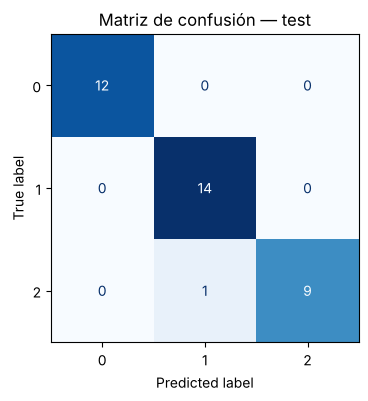

In [4]:
y_pred = model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy : {test_accuracy:.4f}")
print(f"F1 macro : {test_f1_macro:.4f}\n")
print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Matriz de confusión — test")
plt.show()

**Análisis:**

- **Coherencia con CV:** sí. Accuracy en test = 0.972 (35 de 36 aciertos) frente a 0.979 ± 0.028 en validación cruzada; la diferencia (0.7 puntos) es mucho menor que la variabilidad entre folds. F1 macro = 0.971.
- **Clases confundidas:** hay un único error: una muestra de la **clase 2** clasificada como **clase 1** (recall de la clase 2 = 0.90; precisión de la clase 1 = 0.933). La clase 0 se clasifica perfectamente.
- **Sobreajuste:** no hay evidencia material. El rendimiento en test coincide con el de validación y la brecha train–validación era de ~2 puntos. Con solo 36 muestras, un error cambia la accuracy en 2.8 puntos, así que la estimación tiene bastante incertidumbre.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    missing = [c for c in feature_columns if c not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    X = records[feature_columns].copy()              # ordena las columnas como en el entrenamiento
    out = pd.DataFrame(index=records.index)
    out["prediction"] = model.predict(X)
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X)
        for i, cls in enumerate(model.classes_):
            out[f"proba_class_{cls}"] = proba[:, i]
    return out

## 4. Predicción por lotes

In [6]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)

# Prueba de validación de esquema: una columna faltante debe producir un error claro
try:
    predict(new_records.drop(columns=[feature_columns[0]]))
except ValueError as e:
    print("Validación OK ->", e)

batch_predictions.round(3)

Validación OK -> Faltan columnas requeridas: ['alcohol']


,prediction,proba_class_0,proba_class_1,proba_class_2
0,0,1.000,0.000,0.000
1,1,0.007,0.540,0.453
2,0,0.992,0.008,0.000
3,1,0.290,0.707,0.003
4,1,0.033,0.962,0.005


## 5. Reporte final

In [7]:
test_metrics = {
    "model": training_metadata["champion"],
    "accuracy": float(test_accuracy),
    "f1_macro": float(test_f1_macro),
    "n_test": int(len(y_test)),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps(test_metrics, indent=2, ensure_ascii=False))

{
  "model": "logistic_regression",
  "accuracy": 0.9722222222222222,
  "f1_macro": 0.9709618874773139,
  "n_test": 36
}


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | Regresión logística (`C=1`) |
| Accuracy CV | 0.979 (± 0.028) |
| Accuracy test | 0.972 |
| F1 macro test | 0.971 |
| Clases más confundidas | Clase 2 → clase 1 (1 de 10 muestras de la clase 2) |
| Principal limitación | Test de solo 36 muestras (un error = 2.8 puntos) y un único dataset pequeño; no se evaluó robustez ante datos fuera de distribución |

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.